In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
import math
import copy
from numpy.fft import fftn, ifftn, fftshift, ifftshift
from scipy.ndimage import convolve1d, rotate
from scipy.signal import convolve
import nibabel as nib
from FANSI_tools import dipole_kernel, imagesc3d2, compute_rmse 
from Starlet import starlet_transform_3d, inverse_starlet_transform_3d
from Dipolelet import create_annulus_dipolelet_windows, parabolic_dipolelet_decomposition, inverse_parabolic_dipolelet_transform, create_annulus_dipolelet_windows_gaussian
import colorcet as cc
from scipy.ndimage import gaussian_filter
import torch
import time

import eNDI_module_torch
import FANSI_module_torch
import L1_module_torch
import DEMIX_module_torch


plt.rcParams.update({
    #"text.usetex": True,  # Use LaTeX for all text
    #"font.family": "Helvetica",
    "font.serif": ["Times", "Times New Roman"], # Specify Times New Roman
    "font.size": 10,      # Base font size (for colorbar ticks, etc.)
    "text.latex.preamble": r"\usepackage{amsmath}" 
})
plt.rcParams['pdf.fonttype'] = 42      # use TrueType (Type 42), not Type 3
plt.rcParams['ps.fonttype']  = 42

In [2]:
plt.rcParams.update({         # Global font size
    "axes.labelsize": 10,         
    "axes.titlesize": 10,
    "legend.fontsize": 10,
    "xtick.labelsize": 8,         # Often slightly smaller for ticks
    "ytick.labelsize": 8,
})

In [3]:
torch.cuda.set_device(0) 
current_id = torch.cuda.current_device()
print(f"Active GPU ID: {current_id}")
print(f"Active GPU Name: {torch.cuda.get_device_name(current_id)}")
cuda_available = torch.cuda.is_available()
print(f"CUDA Available: {cuda_available}")
if cuda_available:
    # Get the total number of available GPUs
    device_count = torch.cuda.device_count()
    print(f"Number of available GPUs: {device_count}\n")
    
    # Print details for each GPU
    for i in range(device_count):
        device_name = torch.cuda.get_device_name(i)
        device_props = torch.cuda.get_device_properties(i)
        vram_gb = device_props.total_memory / (1024 ** 3)
        
        print(f"Device [{i}]: {device_name}")
        print(f"  - Compute Capability: {device_props.major}.{device_props.minor}")
        print(f"  - Total VRAM: {vram_gb:.2f} GB")
else:
    print("PyTorch cannot find any GPUs. It will default to the CPU.")

Active GPU ID: 0
Active GPU Name: NVIDIA GeForce RTX 5090
CUDA Available: True
Number of available GPUs: 1

Device [0]: NVIDIA GeForce RTX 5090
  - Compute Capability: 12.0
  - Total VRAM: 31.34 GB


In [8]:
def get_slice(data, axis, index):
        if axis == 0:
            return data[index, :, :]
        elif axis == 1:
            return data[:, index, :]
        else: # axis == 2
            return data[:, :, index]
    


def create_geometric_phantom(
    matrix_size, 
    shape_type='sphere', 
    size=(20, 20, 20), 
    center=None, 
    rotation_angles=(0, 0, 0), 
    intensity=1.0
):
    """
    Generates a 3D geometric phantom (sphere, cube, or cylinder) with specified
    size, position, and rotation.

    Args:
        matrix_size (tuple): The shape of the output 3D array (e.g., (160, 160, 160)).
        shape_type (str): 'sphere', 'cube', or 'cylinder'.
        size (tuple or int): Dimensions of the shape.
                             - For 'sphere': (radius,)
                             - For 'cube': (side_x, side_y, side_z)
                             - For 'cylinder': (radius, height)
        center (tuple, optional): The (x, y, z) center of the shape. 
                                  Defaults to the matrix center.
        rotation_angles (tuple, optional): Euler angles (phi, theta, psi) in degrees
                                           for rotation around Z, Y, X axes respectively.
        intensity (float, optional): The value to fill the shape with.

    Returns:
        np.ndarray: A 3D array containing the geometric phantom.
    """
    if center is None:
        center = tuple(n // 2 for n in matrix_size)

    # 1. Create a coordinate grid centered at the specified location
    z, y, x = np.indices(matrix_size)
    x_c = x - center[0]
    y_c = y - center[1]
    z_c = z - center[2]
    
    # Flatten the coordinates for matrix multiplication
    coords = np.vstack([x_c.ravel(), y_c.ravel(), z_c.ravel()])

    # 2. Create the 3D rotation matrix from Euler angles
    phi, theta, psi = np.deg2rad(rotation_angles)
    
    # Rotation matrix for Z-axis (phi)
    Rz = np.array([[np.cos(phi), -np.sin(phi), 0],
                   [np.sin(phi),  np.cos(phi), 0],
                   [0,            0,           1]])
    
    # Rotation matrix for Y-axis (theta)
    Ry = np.array([[np.cos(theta),  0, np.sin(theta)],
                   [0,              1, 0],
                   [-np.sin(theta), 0, np.cos(theta)]])

    # Rotation matrix for X-axis (psi)
    Rx = np.array([[1, 0,             0],
                   [0, np.cos(psi), -np.sin(psi)],
                   [0, np.sin(psi),  np.cos(psi)]])

    # Combined rotation matrix (Z-Y-X convention)
    R = Rz @ Ry @ Rx
    
    # 3. Apply the inverse rotation to the coordinate grid
    # (This is equivalent to rotating the object itself)
    rotated_coords = R.T @ coords
    x_rot = rotated_coords[0, :].reshape(matrix_size)
    y_rot = rotated_coords[1, :].reshape(matrix_size)
    z_rot = rotated_coords[2, :].reshape(matrix_size)

    # 4. Define the shape using its geometric equation on the rotated grid
    mask = np.zeros(matrix_size, dtype=bool)
    if shape_type.lower() == 'sphere':
        radius = size[0]
        mask = (x_rot**2 + y_rot**2 + z_rot**2) <= radius**2
        
    elif shape_type.lower() == 'cube':
        sx, sy, sz = size[0]/2, size[1]/2, size[2]/2
        mask = (np.abs(x_rot) <= sx) & (np.abs(y_rot) <= sy) & (np.abs(z_rot) <= sz)

    elif shape_type.lower() == 'cylinder':
        radius, height = size[0], size[1]/2
        # A cylinder aligned along the Z-axis in its own coordinate system
        mask = (x_rot**2 + y_rot**2 <= radius**2) & (np.abs(z_rot) <= height)
        
    else:
        raise ValueError("shape_type must be 'sphere', 'cube', or 'cylinder'")

    # 5. Create the final phantom
    phantom = np.zeros(matrix_size, dtype=np.float64)
    phantom[mask] = intensity
    
    return phantom

In [4]:
import torch
import torch.nn.functional as F
import math

class ComputeXSIM(torch.nn.Module):
    def __init__(self, sw=(3, 3, 3), sigma=1.5, device='cuda', phs_scale =1):
        """
        Initializes the SSIM module, precomputing the separable Gaussian kernels
        to ensure maximum speed inside an optimization loop.
        """
        super().__init__()
        self.device = device
        self.paddings = list(sw)
        
        # Constants for QSM
        L = 1.0 * phs_scale
        self.C1 = (0.01 * 1.0*L) ** 2
        self.C2 = (0.001 * 1.0*L) ** 2
        
        # Precompute 1D Gaussian kernels for separable convolution
        kernels = []
        for r in sw:
            x = torch.arange(-r, r + 1, dtype=torch.float64, device=device)
            kernel = torch.exp(-(x ** 2) / (2 * sigma ** 2))
            kernel = kernel / kernel.sum() # Normalize
            kernels.append(kernel)
            
        # Reshape for 3D separable conv: (out_channels, in_channels, kD, kH, kW)
        # Depth (Z), Height (Y), Width (X)
        self.register_buffer('kz', kernels[0].view(1, 1, -1, 1, 1))
        self.register_buffer('ky', kernels[1].view(1, 1, 1, -1, 1))
        self.register_buffer('kx', kernels[2].view(1, 1, 1, 1, -1))

    def _blur(self, x):
        """Applies fast separable 3D Gaussian blur matching scipy's 'reflect' boundary."""
        pd, ph, pw = self.paddings
        # F.pad format for 3D: (pad_left, pad_right, pad_top, pad_bottom, pad_front, pad_back) -> W, H, D
        x = F.pad(x, (pw, pw, ph, ph, pd, pd), mode='reflect')
        x = F.conv3d(x, self.kz)
        x = F.conv3d(x, self.ky)
        x = F.conv3d(x, self.kx)
        return x

    def forward(self, img1, img2, mask=None):
        """
        Calculates SSIM while strictly managing GPU memory via `del`.
        """
        # 1. Formatting
        if img1.ndim == 3:
            img1 = img1.unsqueeze(0).unsqueeze(0)
        if img2.ndim == 3:
            img2 = img2.unsqueeze(0).unsqueeze(0)
            
        # 2. Means
        mu1 = self._blur(img1)
        mu1_sq = mu1 ** 2
        
        mu2 = self._blur(img2)
        mu2_sq = mu2 ** 2
        
        mu1_mu2 = mu1 * mu2
        del mu1, mu2  # Free intermediate blurs immediately
        
        # 3. Variances / Covariance
        img1_sq = img1 ** 2
        sigma1_sq = self._blur(img1_sq) - mu1_sq
        del img1_sq # Free squared image
        
        img2_sq = img2 ** 2
        sigma2_sq = self._blur(img2_sq) - mu2_sq
        del img2_sq
        
        img12 = img1 * img2
        sigma12 = self._blur(img12) - mu1_mu2
        del img12 
        
        # 4. SSIM Calculation
        numerator = (2.0 * mu1_mu2 + self.C1) * (2.0 * sigma12 + self.C2)
        del mu1_mu2, sigma12  
        
        denominator = (mu1_sq + mu2_sq + self.C1) * (sigma1_sq + sigma2_sq + self.C2)
        del mu1_sq, mu2_sq, sigma1_sq, sigma2_sq 
        
        ssim_map = numerator / denominator
        del numerator, denominator 
        
        # Remove batch and channel dims for masking
        ssim_map = ssim_map.squeeze()
        
        # 5. Masking and Output
        if mask is None:
            mask = img2.squeeze() != 0
        else:
            mask = mask.squeeze().bool()
            
        mssim = ssim_map[mask].mean()
        
        # Pass final outputs to CPU. 
        # Note: If you need to call .backward() on mssim for your solver, 
        # do NOT detach it, just move it to cpu via .cpu().
        mssim_out = mssim.cpu()
        ssim_map_out = ssim_map.cpu()
        
        del ssim_map, mssim
        
        return mssim_out, ssim_map_out

In [5]:
#---------- Data from FANSI ------------
chiData_COSMOS = sio.loadmat("Fansi_Data/chi_cosmos.mat")
maskUseData = sio.loadmat("Fansi_Data/msk.mat")
spatialResData = sio.loadmat("Fansi_Data/spatial_res.mat")
chiData_STI = sio.loadmat("Fansi_Data/chi_sti.mat")
magnData = sio.loadmat("Fansi_Data/magn.mat")
phs_tissueData = sio.loadmat("Fansi_Data/phs_tissue.mat")

chi_cosmos = chiData_COSMOS["chi_cosmos"].astype(np.float32) # COSMOS ground-truth QSM
chi_13 = chiData_STI["chi_13"].astype(np.float32) # X13 from STI
chi_23 = chiData_STI["chi_23"].astype(np.float32) # X23 from STI
chi_33 = chiData_STI["chi_33"].astype(np.float32) # X33 from STI
spatialRes = spatialResData["spatial_res"].astype(np.float64)[0] # [255/240,255/240,180/168]
maskUse = maskUseData["msk"] # Brain mask from BET
magnUse = magnData["magn"]
phs_tissue = phs_tissueData["phs_tissue"]
#------------NData--------------

# nifti_sti = nib.load("Fansi_Data/chi_sti_filt.nii")
# nifti_dti = nib.load("Fansi_Data/chi_dti_filt.nii")
# sti_data = nifti_sti.get_fdata()
# dti_data = nifti_dti.get_fdata()

N = chi_cosmos.shape
# N_sti = sti_data[:,:,:,0].shape
# N_dti = dti_data[:,:,:,0].shape

TE = 25e-3  #25ms
B0 = 2.8936
gyro = 2 * np.pi * 42.58  #ppm-to-radian scaling factor
phs_scale = TE *gyro * B0
N = chi_cosmos.shape
FOV = np.array(N) * np.array(spatialRes)
kernel = dipole_kernel(N, FOV)
D_qsm = fftshift(dipole_kernel(N, spatialRes))

chi_cosmos = chi_cosmos - np.mean(chi_cosmos)

pcosmos = np.real(np.fft.ifftn(kernel * np.fft.fftn(chi_cosmos)))
pcosmos_masked = pcosmos*maskUse


p33 = np.real(ifftn(kernel * fftn(chi_33)))


ky_vec = np.arange(-N[1]//2, N[1]//2)
kx_vec = np.arange(-N[0]//2, N[0]//2)
kz_vec = np.arange(-N[2]//2, N[2]//2)
Kx, Ky, Kz = np.meshgrid(kx_vec, ky_vec, kz_vec, indexing='ij')


Kx_norm = (Kx / np.max(np.abs(Kx))) / spatialRes[0]
Ky_norm = (Ky / np.max(np.abs(Ky))) / spatialRes[1]
Kz_norm = (Kz / np.max(np.abs(Kz))) / spatialRes[2]

K2 = Kx_norm**2 + Ky_norm**2 + Kz_norm**2
K2[K2 == 0] = np.finfo(float).eps


kernel_13 = Kx_norm * Kz_norm / K2
p13 = np.real(ifftn(fftshift(kernel_13) * fftn(chi_13)))

kernel_23 = Ky_norm * Kz_norm / K2
p23 = np.real(ifftn(fftshift(kernel_23) * fftn(chi_23)))


pQ = p13 + p23
pSTI = p33 - pQ

In [73]:
mag_base = chi_cosmos - np.min(chi_cosmos)
mag_base = mag_base / np.max(mag_base)* maskUse
pcosmos_base = np.real(np.fft.ifftn(kernel * np.fft.fftn(chi_cosmos)))


chi_complete = chi_cosmos + (1 - maskUse) * 2
#phase_ppm_true = np.real(np.fft.ifftn(kernel * np.fft.fftn(chi_complete)))



psi_star = np.zeros_like(pcosmos_base)
#psi_star = np.zeros_like(pcosmos_base)
#jump_size = 2*np.pi
jump_size_radians = 2
jump_size_ppm = 1
psi_star[N[0]//2, N[1]//2+20, N[2]//2] = 2*jump_size_ppm
psi_star[N[0]//2, N[1]//2-45, N[2]//2] = 2*jump_size_ppm
psi_star[N[0]//2, N[1]//2+40, N[2]//2-20] = -2*jump_size_ppm
psi_star[N[0]//2, N[1]//2+40, N[2]//2+25] = -2*jump_size_ppm
psi_star[N[0]//2 , N[1]//2, N[2]//2+10] = -1*jump_size_ppm
psi_star[N[0]//2 , N[1]//2, N[2]//2-10] = 1*jump_size_ppm


#psi_total = phase_noisy+psi_star+0.3*sphere_phantom_1+0.1*sphere_phantom_2


np.random.seed(47)
SNR1 = 100
noise1 = 1 / SNR1
signal1 = mag_base * np.exp(1j * pcosmos_base * phs_scale) + noise1 * (np.random.randn(*N) + 1j * np.random.randn(*N))
#signal = mag_base * np.exp(1j * pcosmos_base * phs_scale) + noise * (np.random.randn(*N) + 1j * np.random.randn(*N))
phaseNoisy1 = np.angle(signal1, deg=False) / phs_scale
magnNoise1 = np.abs(signal1) * maskUse

SNR2 = 40
noise2 = 1 / SNR2
signal2 = mag_base * np.exp(1j * pcosmos_base * phs_scale) + noise2 * (np.random.randn(*N) + 1j * np.random.randn(*N))
#signal = mag_base * np.exp(1j * pcosmos_base * phs_scale) + noise * (np.random.randn(*N) + 1j * np.random.randn(*N))
phaseNoisy2 = np.angle(signal2, deg=False) / phs_scale
magnNoise2 = np.abs(signal2) * maskUse



sphere_phantom_1 = create_geometric_phantom(
    matrix_size=N,
    shape_type='sphere',
    size=(4, 4, 4), # Made it a bit larger
    center=(N[0]//2+10, N[1]//2 -35, N[2]//2),
    intensity=0.33 # The intensity is now in ppm (phase units)
)

sphere_phantom_2 = create_geometric_phantom(
    matrix_size=N,
    shape_type='sphere',
    size=(4, 4, 4), # Made it a bit larger
    center=(N[0]//2-15, N[1]//2 +45, N[2]//2),
    intensity=-0.33 # The intensity is now in ppm (phase units)
)

sphere_phantom_3 = create_geometric_phantom(
    matrix_size=N,
    shape_type='sphere',
    size=(4, 4, 4), # Made it a bit larger
    center=(N[0]//2+10, N[1]//2 +45, N[2]//2),
    intensity=0.33 # The intensity is now in ppm (phase units)
)

cylinder_phantom_1 = create_geometric_phantom(
    matrix_size=N,
    shape_type='cylinder',
    size=(8, 8, 8), # Made it a bit larger
    center=(N[0]//2+10, N[1]//2 -35, N[2]//2),
    rotation_angles = (45,45,45),
    intensity=0.5 # The intensity is now in ppm (phase units)
)

cylinder_phantom_2 = create_geometric_phantom(
    matrix_size=N,
    shape_type='cylinder',
    size=(8, 8, 8), # Made it a bit larger
    center=(N[0]//2-25, N[1]//2+25, N[2]//2),
    rotation_angles = (30,30,30),
    intensity=-0.5 # The intensity is now in ppm (phase units)
)

pcosmos_artifact = np.real(np.fft.ifftn(kernel * np.fft.fftn(chi_cosmos+sphere_phantom_1+sphere_phantom_2+sphere_phantom_3)))
SNR3 = 40
noise3 = 1 / SNR3
signal3 = mag_base * np.exp(1j * (pcosmos_artifact) * phs_scale) + noise2 * (np.random.randn(*N) + 1j * np.random.randn(*N))
#signal = mag_base * np.exp(1j * pcosmos_base * phs_scale) + noise * (np.random.randn(*N) + 1j * np.random.randn(*N))
phaseNoisy3 = np.angle(signal3, deg=False) / phs_scale
magnNoise3 = np.abs(signal3) * maskUse




exp1 = pcosmos_base #Noiseless

exp2 = phaseNoisy1 # SNR100

exp3 = phaseNoisy2 # SNR40

exp4 = pcosmos_base+psi_star #Phase Jumps

exp5 = pcosmos_base+cylinder_phantom_1+cylinder_phantom_2 #Cylinders

exp6 = pcosmos_base+sphere_phantom_1+sphere_phantom_2+sphere_phantom_3 # Spheres

exp7 = phs_tissue # In vivo

exp8 = pSTI #STI

exp9 = -pQ #Off-diagonal terms

exp10 = pcosmos_base * maskUse #Masking

exp11 = phaseNoisy3



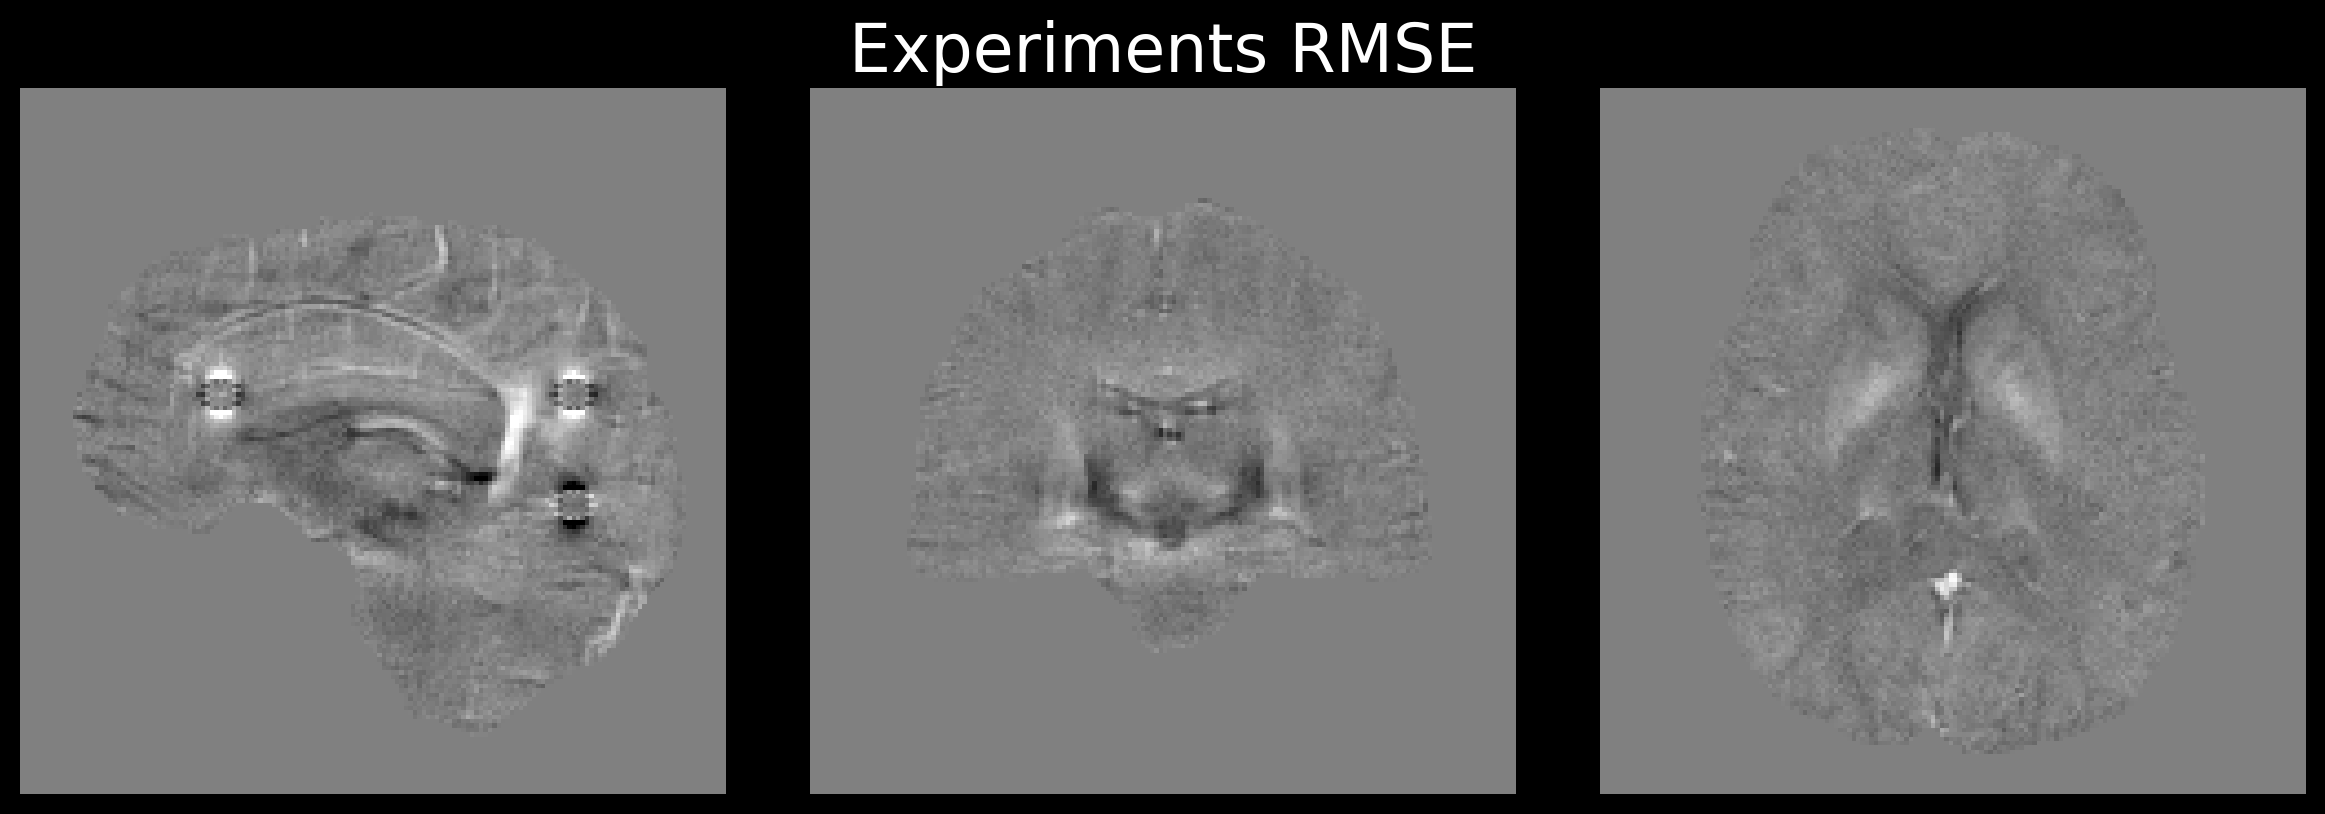

In [74]:

imagesc3d2(((exp11))*maskUse,  tuple(x // 2 for x in N),cmap='grey', contrast=[-0.1,0.1], fig_num=2, rot_deg=[90,90,-90], avg_size=0, title_fig=f"Experiments RMSE")

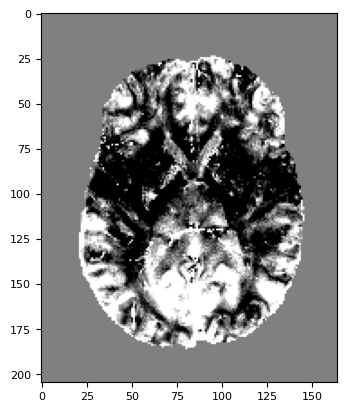

In [10]:

chi_sim2 = nib.load("SIM2_Data/Chi.nii")
freq_sim2 = nib.load("SIM2_Data/Frequency.nii")
magn_sim2 = nib.load("SIM2_Data/Magnitude.nii")
mask_sim2 = nib.load("SIM2_Data/MaskBrainExtracted.nii")
#phase_sim2 = nib.load("SIM2_Data/Phase.nii")
segm_sim2 = nib.load("SIM2_Data/Segmentation.nii")
chi_data = chi_sim2.get_fdata()
freq_data = freq_sim2.get_fdata()



magn_data = magn_sim2.get_fdata()
mask_data = mask_sim2.get_fdata()

#phase_data = phase_sim2.get_fdata()
segm_data = segm_sim2.get_fdata()


tv_sim2 = nib.load("SIM2_Data/tv.nii")
ndi_sim2 = nib.load("SIM2_Data/ndi.nii")
tv_data = tv_sim2.get_fdata()
ndi_data = ndi_sim2.get_fdata()

phase_total_sim2 = nib.load("SIM2_Data/Phase_SIM2.nii")
mag_total_sim2 = nib.load("SIM2_Data/Data_magn_SIM2.nii")

phase_total_data = phase_total_sim2.get_fdata()
mag_total_data = mag_total_sim2.get_fdata()






N_pad = (256, 256, 256)
TEv = np.array([4e-3,12e-3,20e-3,28e-3])
N2 = freq_data.shape 
TE = 8e-3  #25ms
#4E-3 para ISMRM/ISBI
#10E-3 recomendaod por carlos, aunque poco realosta
B0 = 7
gyro = 2 * np.pi * 42.58  #ppm-to-radian scaling factor
phs_scale = TE *gyro * B0

phs_sim = freq_data*2*np.pi*TE

plt.imshow(rotate(phs_sim[:,:,103],90),cmap='grey',vmin = -0.1, vmax = 0.1)
TEv = np.array([4e-3,12e-3,20e-3,28e-3])

In [11]:
spatialRes2 = np.array([1,1,1])
N2 = freq_data.shape
FOV2 = np.array(N2) * np.array(spatialRes2)
kernel2 = dipole_kernel(N2, FOV2)
D_qsm2 = fftshift(dipole_kernel(N2, spatialRes2))

magn_sim = magn_data[:,:,:,1]/np.max(magn_data)

# 1. Define your original and new padded shapes
N2 = freq_data.shape  # This is (164, 205, 205)
N_pad = (256, 256, 256)

phs_padded = np.zeros(N_pad, dtype=chi_data.dtype)
phs_padded[0:N2[0], 0:N2[1], 0:N2[2]] = (phs_sim)

#magn_padded = np.zeros(N_pad, dtype=magn_use2.dtype)
# Place the original data in the 'corner'
#magn_padded[0:N2[0], 0:N2[1], 0:N2[2]] = magn_use2

#magn_sim_padded = np.zeros(N_pad, dtype=magn_sim.dtype)
# Place the original data in the 'corner'
#magn_sim_padded[0:N2[0], 0:N2[1], 0:N2[2]] = magn_sim


chi_padded = np.zeros(N_pad, dtype=chi_data.dtype)
# Place the original data in the 'corner'
chi_padded[0:N2[0], 0:N2[1], 0:N2[2]] = chi_data



# 3. Pad the mask data
mask_padded = np.zeros(N_pad, dtype=mask_data.dtype)
mask_padded[0:N2[0], 0:N2[1], 0:N2[2]] = mask_data

# 4. Pad the magnitude data
#magn_padded = np.zeros(N_pad, dtype=magn_data.dtype)
#magn_padded[0:N2[0], 0:N2[1], 0:N2[2]] = magn_data


# The spatial resolution (mm/voxel) stays the same
spatialRes_pad = spatialRes2  # Still [1, 1, 1]

# The matrix size (N) and Field of View (FOV) are now larger
N_pad_array = np.array(N_pad)
FOV_pad = N_pad_array * spatialRes_pad

# Recalculate your kernels with the new 256x256x256 shape
kernel_pad = dipole_kernel(N_pad, FOV_pad)
D_qsm_pad = fftshift(dipole_kernel(N_pad, spatialRes_pad))

print(f"New padded kernel shape: {kernel_pad.shape}")

New padded kernel shape: (256, 256, 256)


In [ ]:
magn_prime = magn_data[:,:,:,:]/np.max(magn_data)
wPrime = np.sum(magn_prime**2 * TEv,axis = 3)/np.sum(magn_prime * TEv,axis=3)
wPrime_padded = np.zeros(N_pad, dtype=wPrime.dtype)
wPrime_padded[0:N2[0], 0:N2[1], 0:N2[2]] = wPrime

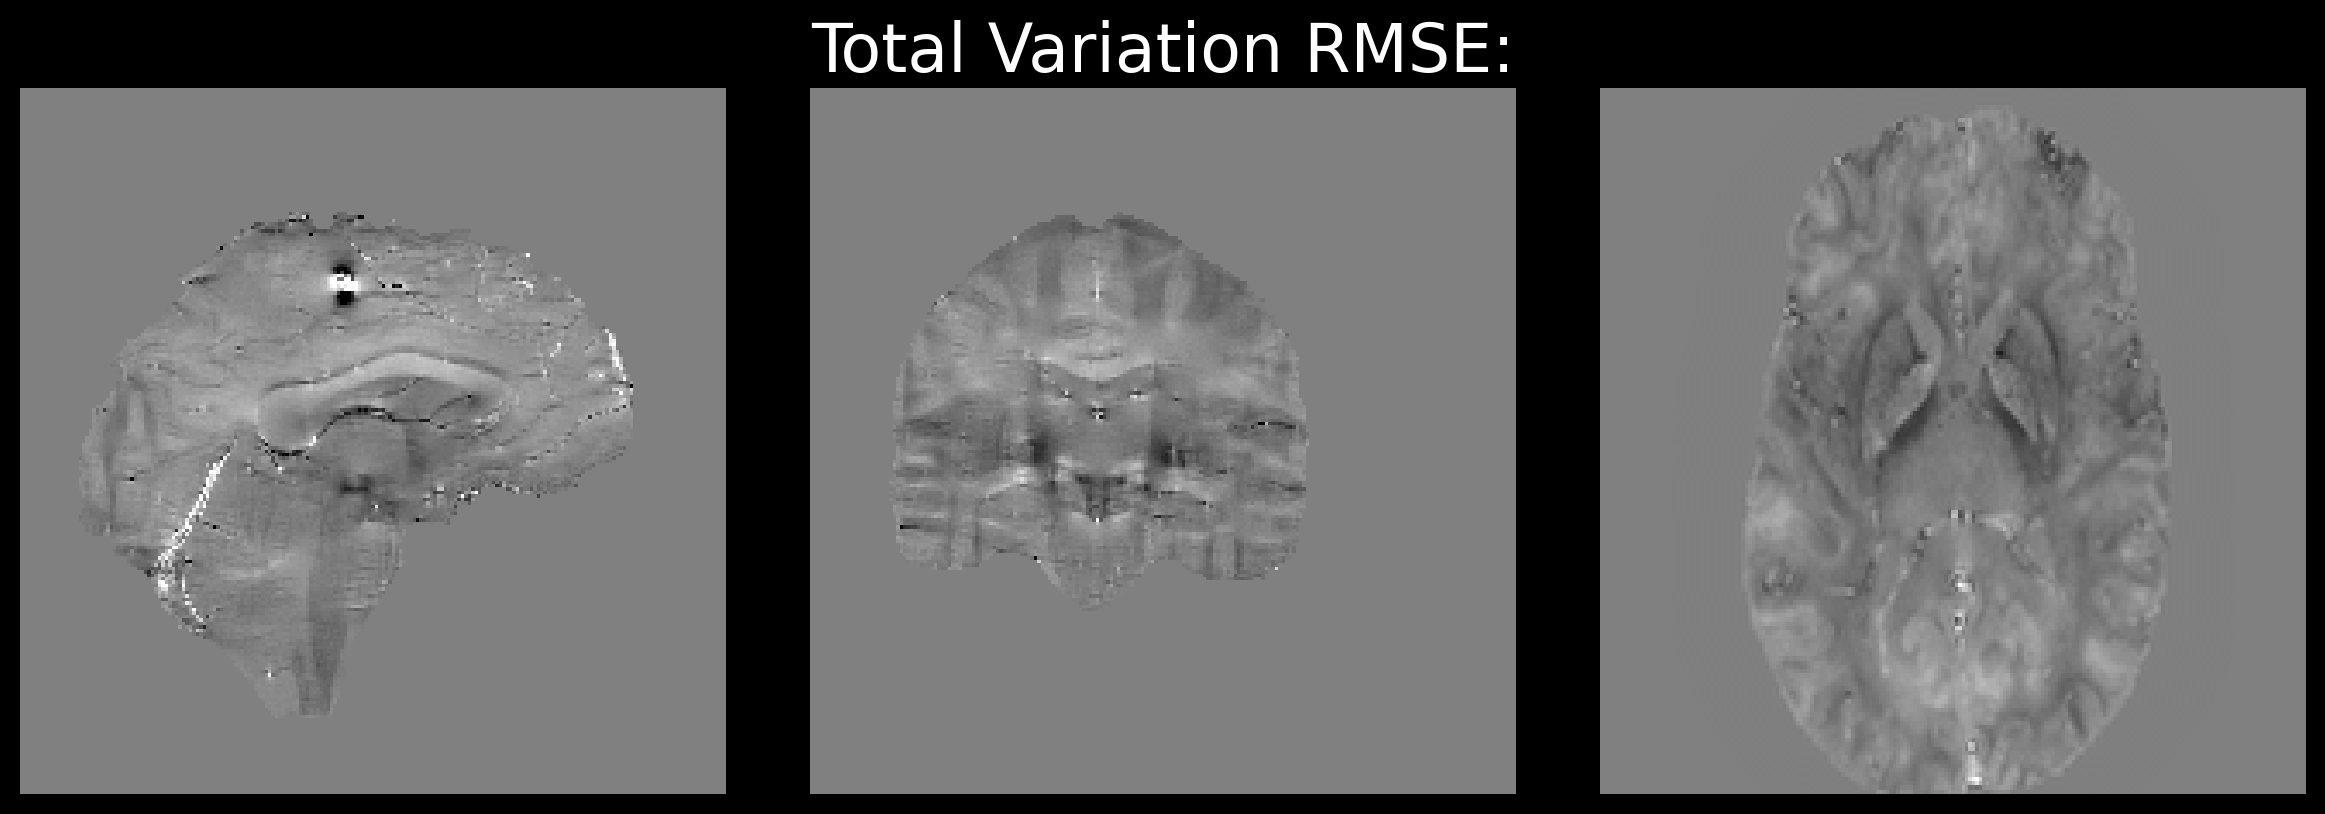

In [13]:
imagesc3d2(phs_sim,  tuple(x // 2 for x in N2),cmap='grey', contrast=[-1,1], fig_num=4, rot_deg=[90,90,90], scale_fig=[-0.12,0.12, -0.12, 0.12], avg_size=0, title_fig=f"Total Variation RMSE:")


In [36]:
# --- Run Reconstruction ---
params = {}
params["K"] = kernel_pad
#params["input"] = pdf
params["input"] = phs_padded
params["alpha"] = 1e-4


#params["beta"] = 1e6
#params["muh"] = 50
params["isNonlinear"] = True
params["weight"] =wPrime_padded
params["mask"] = mask_padded
params["maxOuterIter"] = 1000
params["tolUpdate"] = 1e-10
params["chi_cosmos"] = chi_padded*phs_scale
#params["chi_cosmos"] = chiGt
params["isXSIM"] = True
params["phsScale"] = phs_scale
#params["phi_init"] = out_pdf["phi"]/phs_scale
outtv = FANSI_module_torch.fansiTV(params)
outtvx = outtv['x']/phs_scale

#Best RMSE Achieved: 25.640954
#Best Hyperparameters:
#    alpha:   8.942371e-05
#    lambda:  8.855549e-04 CON MASCARA
torch.cuda.empty_cache()


Iter: 1   Update: 100.000000   NRMSE: 95.4938%   XSIM: 0.0116
Iter: 2   Update: 63.040916   NRMSE: 87.6362%   XSIM: 0.0671
Iter: 3   Update: 25.577535   NRMSE: 83.9981%   XSIM: 0.1041
Iter: 4   Update: 18.570082   NRMSE: 80.7493%   XSIM: 0.1425
Iter: 5   Update: 14.712435   NRMSE: 77.7492%   XSIM: 0.1808
Iter: 6   Update: 12.257518   NRMSE: 74.9800%   XSIM: 0.2182
Iter: 7   Update: 10.534073   NRMSE: 72.4179%   XSIM: 0.2539
Iter: 8   Update: 9.113924   NRMSE: 70.0378%   XSIM: 0.2874
Iter: 9   Update: 7.923739   NRMSE: 67.8271%   XSIM: 0.3185
Iter: 10   Update: 6.937174   NRMSE: 65.7818%   XSIM: 0.3470
Iter: 11   Update: 6.131530   NRMSE: 63.8928%   XSIM: 0.3731
Iter: 12   Update: 5.471530   NRMSE: 62.1504%   XSIM: 0.3968
Iter: 13   Update: 4.931158   NRMSE: 60.5454%   XSIM: 0.4183
Iter: 14   Update: 4.482145   NRMSE: 59.0656%   XSIM: 0.4380
Iter: 15   Update: 4.101532   NRMSE: 57.6978%   XSIM: 0.4559
Iter: 16   Update: 3.768700   NRMSE: 56.4312%   XSIM: 0.4722
Iter: 17   Update: 3.4639

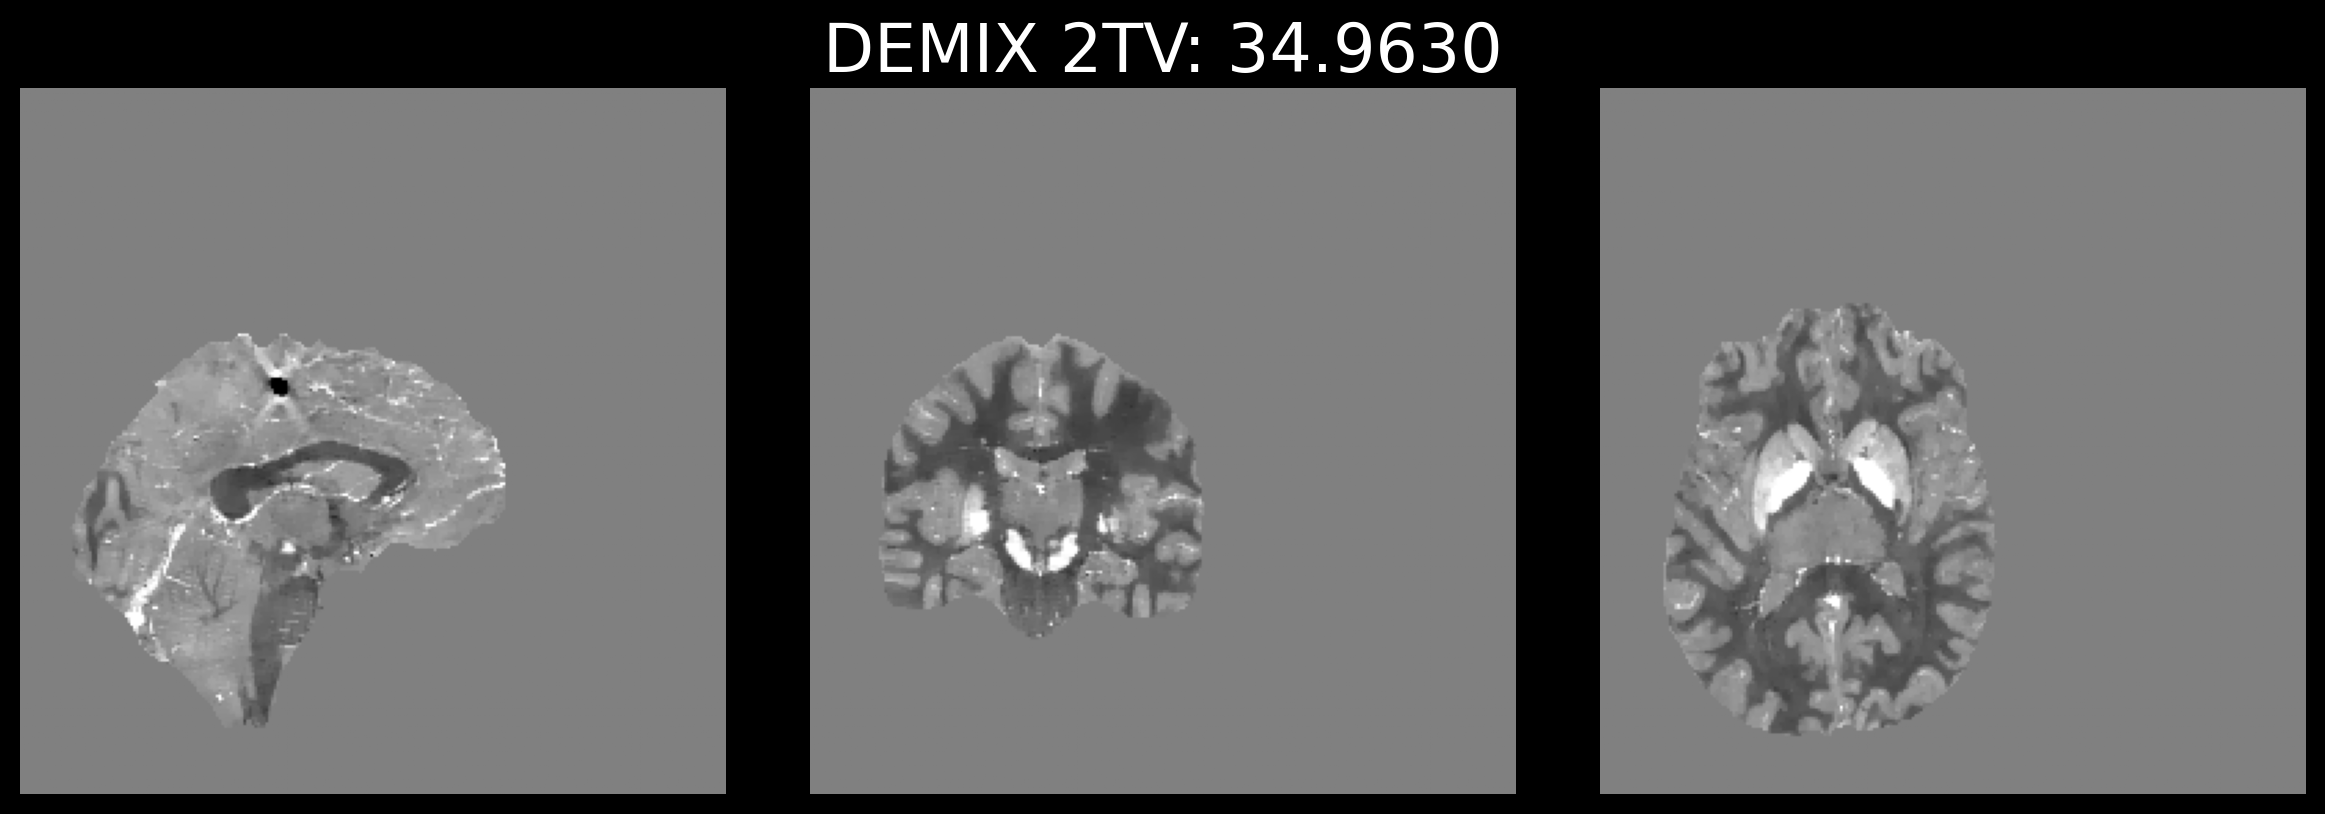

In [35]:
imagesc3d2((outtvx*mask_padded), tuple(x // 2 for x in N2),cmap='grey', contrast=[-0.1,0.1], fig_num=4, rot_deg=[90,90,90], scale_fig=[-0.12,0.12, -0.12, 0.12], avg_size=0, title_fig=f"DEMIX 2TV: {compute_rmse(outtvx*mask_padded,chi_padded*mask_padded):.4f}")


In [40]:
# --- Run Reconstruction ---
params = {}
params["K"] = kernel_pad
#params["input"] = pdf
params["input"] = phs_padded
params["alpha"] = 1e-5


#params["beta"] = 1e6
#params["muh"] = 50
params["isNonlinear"] = False
params["weight"] =wPrime_padded
params["mask"] = mask_padded
params["maxOuterIter"] = 150
params["tolUpdate"] = 1e-10
params["chi_cosmos"] = chi_padded*phs_scale
#params["chi_cosmos"] = chiGt
params["isXSIM"] = True
params["phsScale"] = phs_scale
#params["phi_init"] = out_pdf["phi"]/phs_scale
outndi = eNDI_module_torch.ndiCG_auto(params)
outndix = outndi['x']/phs_scale

#Best RMSE Achieved: 25.640954
#Best Hyperparameters:
#    alpha:   8.942371e-05
#    lambda:  8.855549e-04 CON MASCARA
torch.cuda.empty_cache()


Iter: 0   Update: 100.000000   NRMSE: 78.3526%
Iter: 1   Update: 26.155420   NRMSE: 72.4201%
Iter: 2   Update: 34.023435   NRMSE: 63.9241%
Iter: 3   Update: 14.662843   NRMSE: 60.7966%
Iter: 4   Update: 14.396425   NRMSE: 57.8797%
Iter: 5   Update: 6.978712   NRMSE: 56.5489%
Iter: 6   Update: 7.760102   NRMSE: 55.1367%
Iter: 7   Update: 5.230710   NRMSE: 54.1762%
Iter: 8   Update: 5.553587   NRMSE: 53.2999%
Iter: 9   Update: 3.864752   NRMSE: 52.6963%
Iter: 10   Update: 4.355066   NRMSE: 52.1342%
Iter: 11   Update: 2.555932   NRMSE: 51.8220%
Iter: 12   Update: 3.562214   NRMSE: 51.4769%
Iter: 13   Update: 1.987237   NRMSE: 51.3066%
Iter: 14   Update: 3.270704   NRMSE: 51.0850%
Iter: 15   Update: 1.765993   NRMSE: 50.9966%
Iter: 16   Update: 3.102086   NRMSE: 50.8923%
Iter: 17   Update: 1.543102   NRMSE: 50.8750%
Automatic stop reached!
Regularization Time: 0.6175 seconds
Total Execution Time: 0.9518 seconds


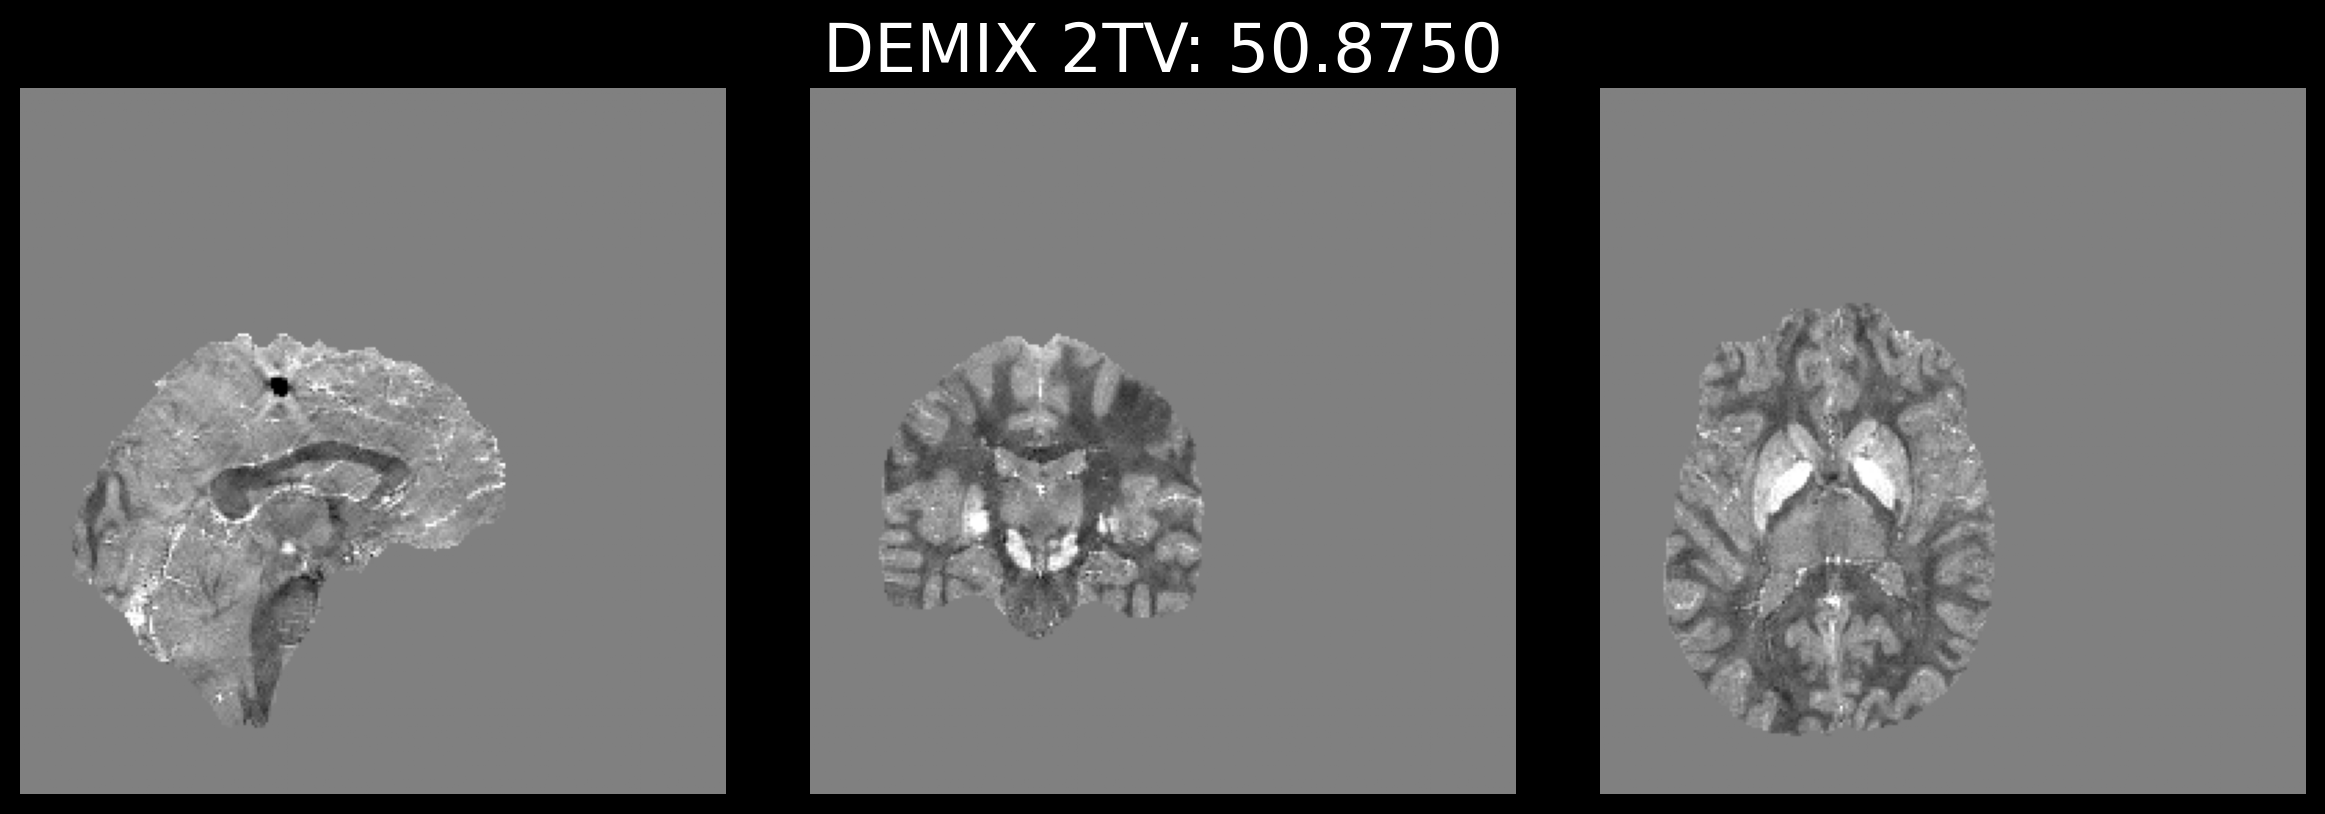

In [41]:
imagesc3d2((outndix*mask_padded), tuple(x // 2 for x in N2),cmap='grey', contrast=[-0.1,0.1], fig_num=4, rot_deg=[90,90,90], scale_fig=[-0.12,0.12, -0.12, 0.12], avg_size=0, title_fig=f"DEMIX 2TV: {compute_rmse(outndix*mask_padded,chi_padded*mask_padded):.4f}")



In [42]:
# Create coordinate grids
x_coords = np.arange(N[0])
y_coords = np.arange(N[1])
z_coords = np.arange(N[2])
X, Y, Z = np.meshgrid(x_coords, y_coords, z_coords, indexing='ij')

chi_bkg_true = np.zeros(N)

# Function to add a spherical susceptibility source
def add_sphere(chi_matrix, center, radius, chi_value):
    dist_sq = (X - center[0])**2 + (Y - center[1])**2 + (Z - center[2])**2
    chi_matrix[dist_sq <= radius**2] = chi_value
    return chi_matrix

# Add a "frontal sinus" (adjust coordinates based on your specific FOV/orientation)
chi_bkg_true = add_sphere(chi_bkg_true, center=(N[0]//2, 30, N[2]//4), radius=30, chi_value=9.4)

# Add "ear canals" or mastoid air cells
chi_bkg_true = add_sphere(chi_bkg_true, center=(N[0]//4, N[1]//2, N[2]//4), radius=12, chi_value=9.4)
chi_bkg_true = add_sphere(chi_bkg_true, center=(3*N[0]//4, N[1]//2, N[2]//4), radius=12, chi_value=9.4)

# Ensure no overlap with the actual brain mask (tissue overrides the background sources)
chi_bkg_true = chi_bkg_true * (1 - maskUse)

# Calculate Background Phase
phase_bkg = np.real(np.fft.ifftn(kernel * np.fft.fftn(chi_bkg_true)))

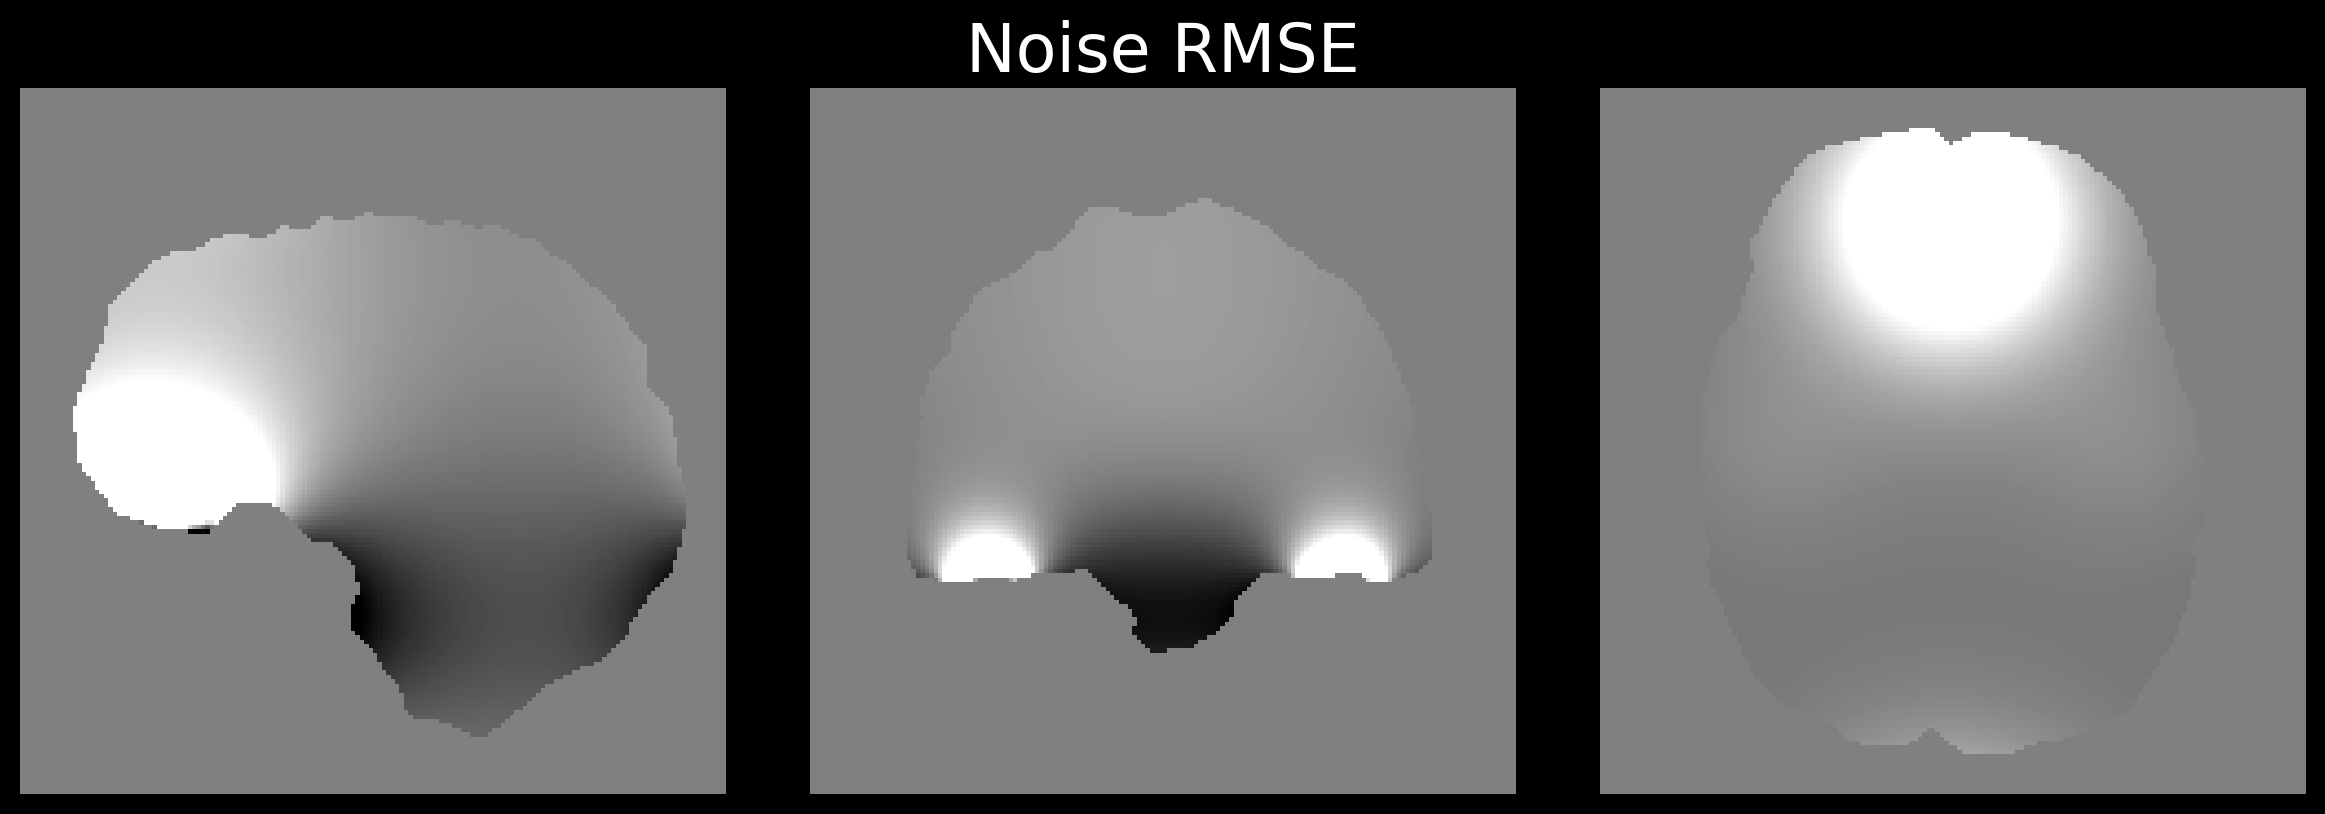

In [44]:

imagesc3d2(((phase_bkg))*maskUse,  tuple(x // 2 for x in N),cmap='grey', contrast=[-1,1], fig_num=2, rot_deg=[90,90,-90], avg_size=0, title_fig=f"Noise RMSE")

In [49]:
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np

def visualize_decomposition_with_sums(
    segmented_coeffs,
    segmented_coarse,
    slice_dim,
    slice_idx,
    data_name="Dipole-let Decomposition",
    title_info="",
    contrast=[-0.01, 0.01],
    cmap='gray',
    cmap_bkg='gray',
    save_path=None,
    text_color='white', 
    aspect='auto',
    units='PPM',
    return_array=False, # <--- Added option to return figure as numpy array
    fontsize=14,        # <--- Added input for setting the fontsize
    rot=90              # <--- Added rotation parameter
):
    num_radial_scales = len(segmented_coeffs)
    if num_radial_scales == 0:
        print("No detail coefficients to plot.")
        return

    angular_keys = list(segmented_coeffs[0].keys())
    num_angular_bands = len(angular_keys)

    num_rows = num_radial_scales + 1
    num_cols = num_angular_bands + 1

    norm = mcolors.Normalize(vmin=contrast[0], vmax=contrast[1])
    cmap_instance = cm.get_cmap(cmap_bkg)
    bg_color = cmap_instance(norm(0))

    fig, axes = plt.subplots(num_rows, num_cols,
                             figsize=(3.5 * num_cols, 3.5 * num_rows),
                             squeeze=False, dpi=150, facecolor=bg_color)
    
    # Combined strings and strip any accidental whitespace
    combined_title = f"{data_name} {title_info}".strip()
    
    if combined_title:
        top_margin = 0.90 # Lowered to bring title closer to plots
        # Lowered y-coordinate from 0.96 to 0.94
        fig.text(0.5, 0.94, combined_title, 
                 color=text_color, fontsize=fontsize + 4, fontweight='bold', ha='center')
    else:
        top_margin = 0.96

    # Apply the dynamic top margin
    plt.subplots_adjust(left=0.02, right=0.98, bottom=0.1, top=top_margin, wspace=0.02, hspace=0.02)

    grid_data = [[None for _ in range(num_cols)] for _ in range(num_rows)]
    grid_titles = [[None for _ in range(num_cols)] for _ in range(num_rows)]
    
    column_sums = [np.zeros_like(segmented_coeffs[0][angular_keys[0]]) for _ in angular_keys]

    for j, scale_segments in enumerate(segmented_coeffs):
        row_sum = np.zeros_like(list(scale_segments.values())[0])
        for m, key in enumerate(angular_keys):
            component = scale_segments.get(key, np.zeros_like(row_sum))
            
            grid_data[j][m] = component
            grid_titles[j][m] = fr"$\mathfrak{{D}}_{{{j},{m}}}$"
            
            row_sum += component
            column_sums[m] += component
            
        grid_data[j][num_cols-1] = row_sum
        grid_titles[j][num_cols-1] = fr"Angular Sum $\mathfrak{{D}}_{{{j},m}}$"

    # Populate Column Sums (Last Row)
    for m, key in enumerate(angular_keys):
        grid_data[num_rows-1][m] = column_sums[m]
        grid_titles[num_rows-1][m] = fr"Radial Sum $\mathfrak{{D}}_{{j,{m}}}$"

    # Populate Residual (Bottom-Right)
    grid_data[num_rows-1][num_cols-1] = segmented_coarse['coarse_full']
    grid_titles[num_rows-1][num_cols-1] = fr"Residual"

    # --- Plotting the Grid ---
    im_ref = None
    for r in range(num_rows):
        for c in range(num_cols):
            ax = axes[r, c]
            data = grid_data[r][c]
            title = grid_titles[r][c]
            
            # Rotation and display
            current_rot = rot[slice_dim] if isinstance(rot, (list, tuple)) else rot
            img_data = rotate(get_slice(data, slice_dim, slice_idx), current_rot)
            im = ax.imshow(img_data, cmap=cmap, vmin=contrast[0], vmax=contrast[1], aspect=aspect)
            ax.axis('off')
            
            # Internal titles (Lowered y to 0.88 to be closer to plots, unified bbox with second function)
            ax.text(0.5, 0.92, title, transform=ax.transAxes, 
                    color=text_color, fontsize=fontsize, va='top', ha='center', weight='bold',
                    bbox=dict(facecolor=bg_color, alpha=0.6, lw=0, pad=2))
            
            if r == 0 and c == 0:
                im_ref = im

    # Scale the colorbar height proportionally based on the provided fontsize
    cbar_height = 0.015 * (fontsize / 14.0)
    cbar_ax = fig.add_axes([0.35, 0.08, 0.30, cbar_height])
    cbar = fig.colorbar(im_ref, cax=cbar_ax, ticks=[], orientation='horizontal')
    cbar.outline.set_linewidth(0.0) 

    # Colorbar fontsize is 0.8 times the input fontsize
    cbar_fontsize = fontsize * 0.8

    # Plot text inside colorbar ends with specified colors
    cbar_ax.text(0.02, 0.5, f'{contrast[0]}', transform=cbar_ax.transAxes, 
                 color='white', fontsize=cbar_fontsize, fontweight='bold', ha='left', va='center')
    cbar_ax.text(0.5, 0.5, units, transform=cbar_ax.transAxes, 
                 color=text_color, fontsize=cbar_fontsize, fontweight='bold', ha='center', va='center')
    cbar_ax.text(0.98, 0.5, f'{contrast[1]}', transform=cbar_ax.transAxes, 
                 color='black', fontsize=cbar_fontsize, fontweight='bold', ha='right', va='center')

    # Handle returning array or saving/showing
    if return_array:
        fig.canvas.draw()
        img_array = np.array(fig.canvas.buffer_rgba())
        plt.close(fig)
        return img_array

    if save_path is not None:
        plt.savefig(save_path, dpi=200, facecolor=bg_color, bbox_inches='tight')
        print(f"Figure saved to: {save_path}")
        plt.close(fig)
    else:
        plt.show()


def visualize_windows_with_sums(
    combined_windows_list,
    slice_dim,
    slice_idx,
    data_name="Dipole-let Decomposition",
    title_info="",
    contrast=[-0.01, 0.01],
    cmap='gray',
    cmap_bkg='gray',
    save_path=None,
    text_color='white', 
    aspect='auto',
    units='Amplitude',
    return_array=False, # <--- Added option to return figure as numpy array
    fontsize=14,        # <--- Added input for setting the fontsize
    rot=90              # <--- Added rotation parameter
):
    num_radial_scales = len(combined_windows_list)
    if num_radial_scales == 0:
        print("No window coefficients to plot.")
        return

    angular_keys = list(combined_windows_list[0].keys())
    num_angular_bands = len(angular_keys)

    num_rows = num_radial_scales + 1
    num_cols = num_angular_bands + 1

    norm = mcolors.Normalize(vmin=contrast[0], vmax=contrast[1])
    cmap_instance = cm.get_cmap(cmap_bkg)
    bg_color = cmap_instance(norm(0))

    fig, axes = plt.subplots(num_rows, num_cols,
                             figsize=(3.5 * num_cols, 3.5 * num_rows),
                             squeeze=False, dpi=150, facecolor=bg_color)
    
    # --- Dynamic Layout and Title ---
    # Combine strings and strip any accidental whitespace
    combined_title = f"{data_name} {title_info}".strip()
    
    if combined_title:
        top_margin = 0.90 # Lowered to bring title closer to plots
        # Lowered y-coordinate from 0.96 to 0.94
        fig.text(0.5, 0.94, combined_title, 
                 color=text_color, fontsize=fontsize + 4, fontweight='bold', ha='center')
    else:
        top_margin = 0.96

    # Apply the dynamic top margin
    plt.subplots_adjust(left=0.02, right=0.98, bottom=0.1, top=top_margin, wspace=0.02, hspace=0.02)

    grid_data = [[None for _ in range(num_cols)] for _ in range(num_rows)]
    grid_titles = [[None for _ in range(num_cols)] for _ in range(num_rows)]
    
    column_sums = [np.zeros_like(combined_windows_list[0][angular_keys[0]]) for _ in angular_keys]
    total_window_sum = np.zeros_like(combined_windows_list[0][angular_keys[0]])

    for j, scale_segments in enumerate(combined_windows_list):
        row_sum = np.zeros_like(list(scale_segments.values())[0])
        for m, key in enumerate(angular_keys):
            
            component = scale_segments.get(key, np.zeros_like(row_sum))
            
            grid_data[j][m] = component
            grid_titles[j][m] = fr"$R_{{{j}}}A_{{{m}}}$"
            
            row_sum += component
            column_sums[m] += component
            total_window_sum += component
            
        grid_data[j][num_cols-1] = row_sum
        grid_titles[j][num_cols-1] = fr"Angular Sum $R_{{{j}}}A_{{m}}$"

    # Populate Column Sums (Last Row)
    for m, key in enumerate(angular_keys):
        grid_data[num_rows-1][m] = column_sums[m]
        grid_titles[num_rows-1][m] = fr"Radial Sum $R_{{j}}A_{{{m}}}$"

    # Populate Residual Window (Bottom-Right)
    # The coarse/residual window in k-space is 1 minus the sum of all detail filters
    residual_window = 1.0 - total_window_sum
    
    grid_data[num_rows-1][num_cols-1] = residual_window
    grid_titles[num_rows-1][num_cols-1] = fr"Residual"

    im_ref = None
    for r in range(num_rows):
        for c in range(num_cols):
            ax = axes[r, c]
            data = grid_data[r][c]
            title = grid_titles[r][c]
            
            # Rotation and display
            current_rot = rot[slice_dim] if isinstance(rot, (list, tuple)) else rot
            img_data = rotate(get_slice(data, slice_dim, slice_idx), current_rot)
            # max_val = np.max(img_data)
            # if max_val > 1e-9:  # Prevent division by zero for empty/zero bands
            #     img_data = img_data / max_val
            im = ax.imshow(img_data, cmap=cmap, vmin=contrast[0], vmax=contrast[1], aspect=aspect)
            ax.axis('off')
            
            # Internal titles (Lowered y to 0.88 to be closer to plots)
            ax.text(0.5, 0.92, title, transform=ax.transAxes, 
                    color=text_color, fontsize=fontsize, va='top', ha='center', weight='bold',
                    bbox=dict(facecolor=bg_color, alpha=0.6, lw=0, pad=2))
            
            if r == 0 and c == 0:
                im_ref = im

    # Scale the colorbar height proportionally based on the provided fontsize
    cbar_height = 0.015 * (fontsize / 14.0)
    cbar_ax = fig.add_axes([0.35, 0.08, 0.30, cbar_height])
    cbar = fig.colorbar(im_ref, cax=cbar_ax, ticks=[], orientation='horizontal')
    cbar.outline.set_linewidth(0.0) 

    # Colorbar fontsize is 0.8 times the input fontsize
    cbar_fontsize = fontsize * 0.8

    # Plot text inside colorbar ends with specified colors
    cbar_ax.text(0.02, 0.5, f'{contrast[0]}', transform=cbar_ax.transAxes, 
                 color='white', fontsize=cbar_fontsize, fontweight='bold', ha='left', va='center')
    cbar_ax.text(0.5, 0.5, units, transform=cbar_ax.transAxes, 
                 color=text_color, fontsize=cbar_fontsize, fontweight='bold', ha='center', va='center')
    cbar_ax.text(0.98, 0.5, f'{contrast[1]}', transform=cbar_ax.transAxes, 
                 color='black', fontsize=cbar_fontsize, fontweight='bold', ha='right', va='center')

    # Handle returning array or saving/showing
    if return_array:
        fig.canvas.draw()
        img_array = np.array(fig.canvas.buffer_rgba())
        plt.close(fig)
        return img_array

    if save_path is not None:
        plt.savefig(save_path, dpi=150, facecolor=bg_color, bbox_inches='tight')
        print(f"Figure saved to: {save_path}")
        plt.close(fig)
    else:
        plt.show()

In [66]:
print("Performing dipolelet decomposition on unwrapped phase (ppm)...")
segmented_coeffs_sim2, segmented_coarse_sim2, windows_ = parabolic_dipolelet_decomposition(
    image_3d=(phs_padded*mask_padded/phs_scale)[0:N2[0], 0:N2[1], 0:N2[2]],
    D_qsm=np.fft.fftshift(kernel2),
    num_radial_scales=3,
    base_angular_bands=3,
    delta0=0.05,
    return_windows = True,
    transform=starlet_transform_3d,
    starlet_filter_type='gaussian', starlet_filter_param=0.5,
    window_type='gaussian', gaussian_width_factor=0.5,reverse_scaling= False,
    scaling_law='static'

)

Performing dipolelet decomposition on unwrapped phase (ppm)...


/tmp/ipykernel_3536/94907567.py:36: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_instance = cm.get_cmap(cmap_bkg)


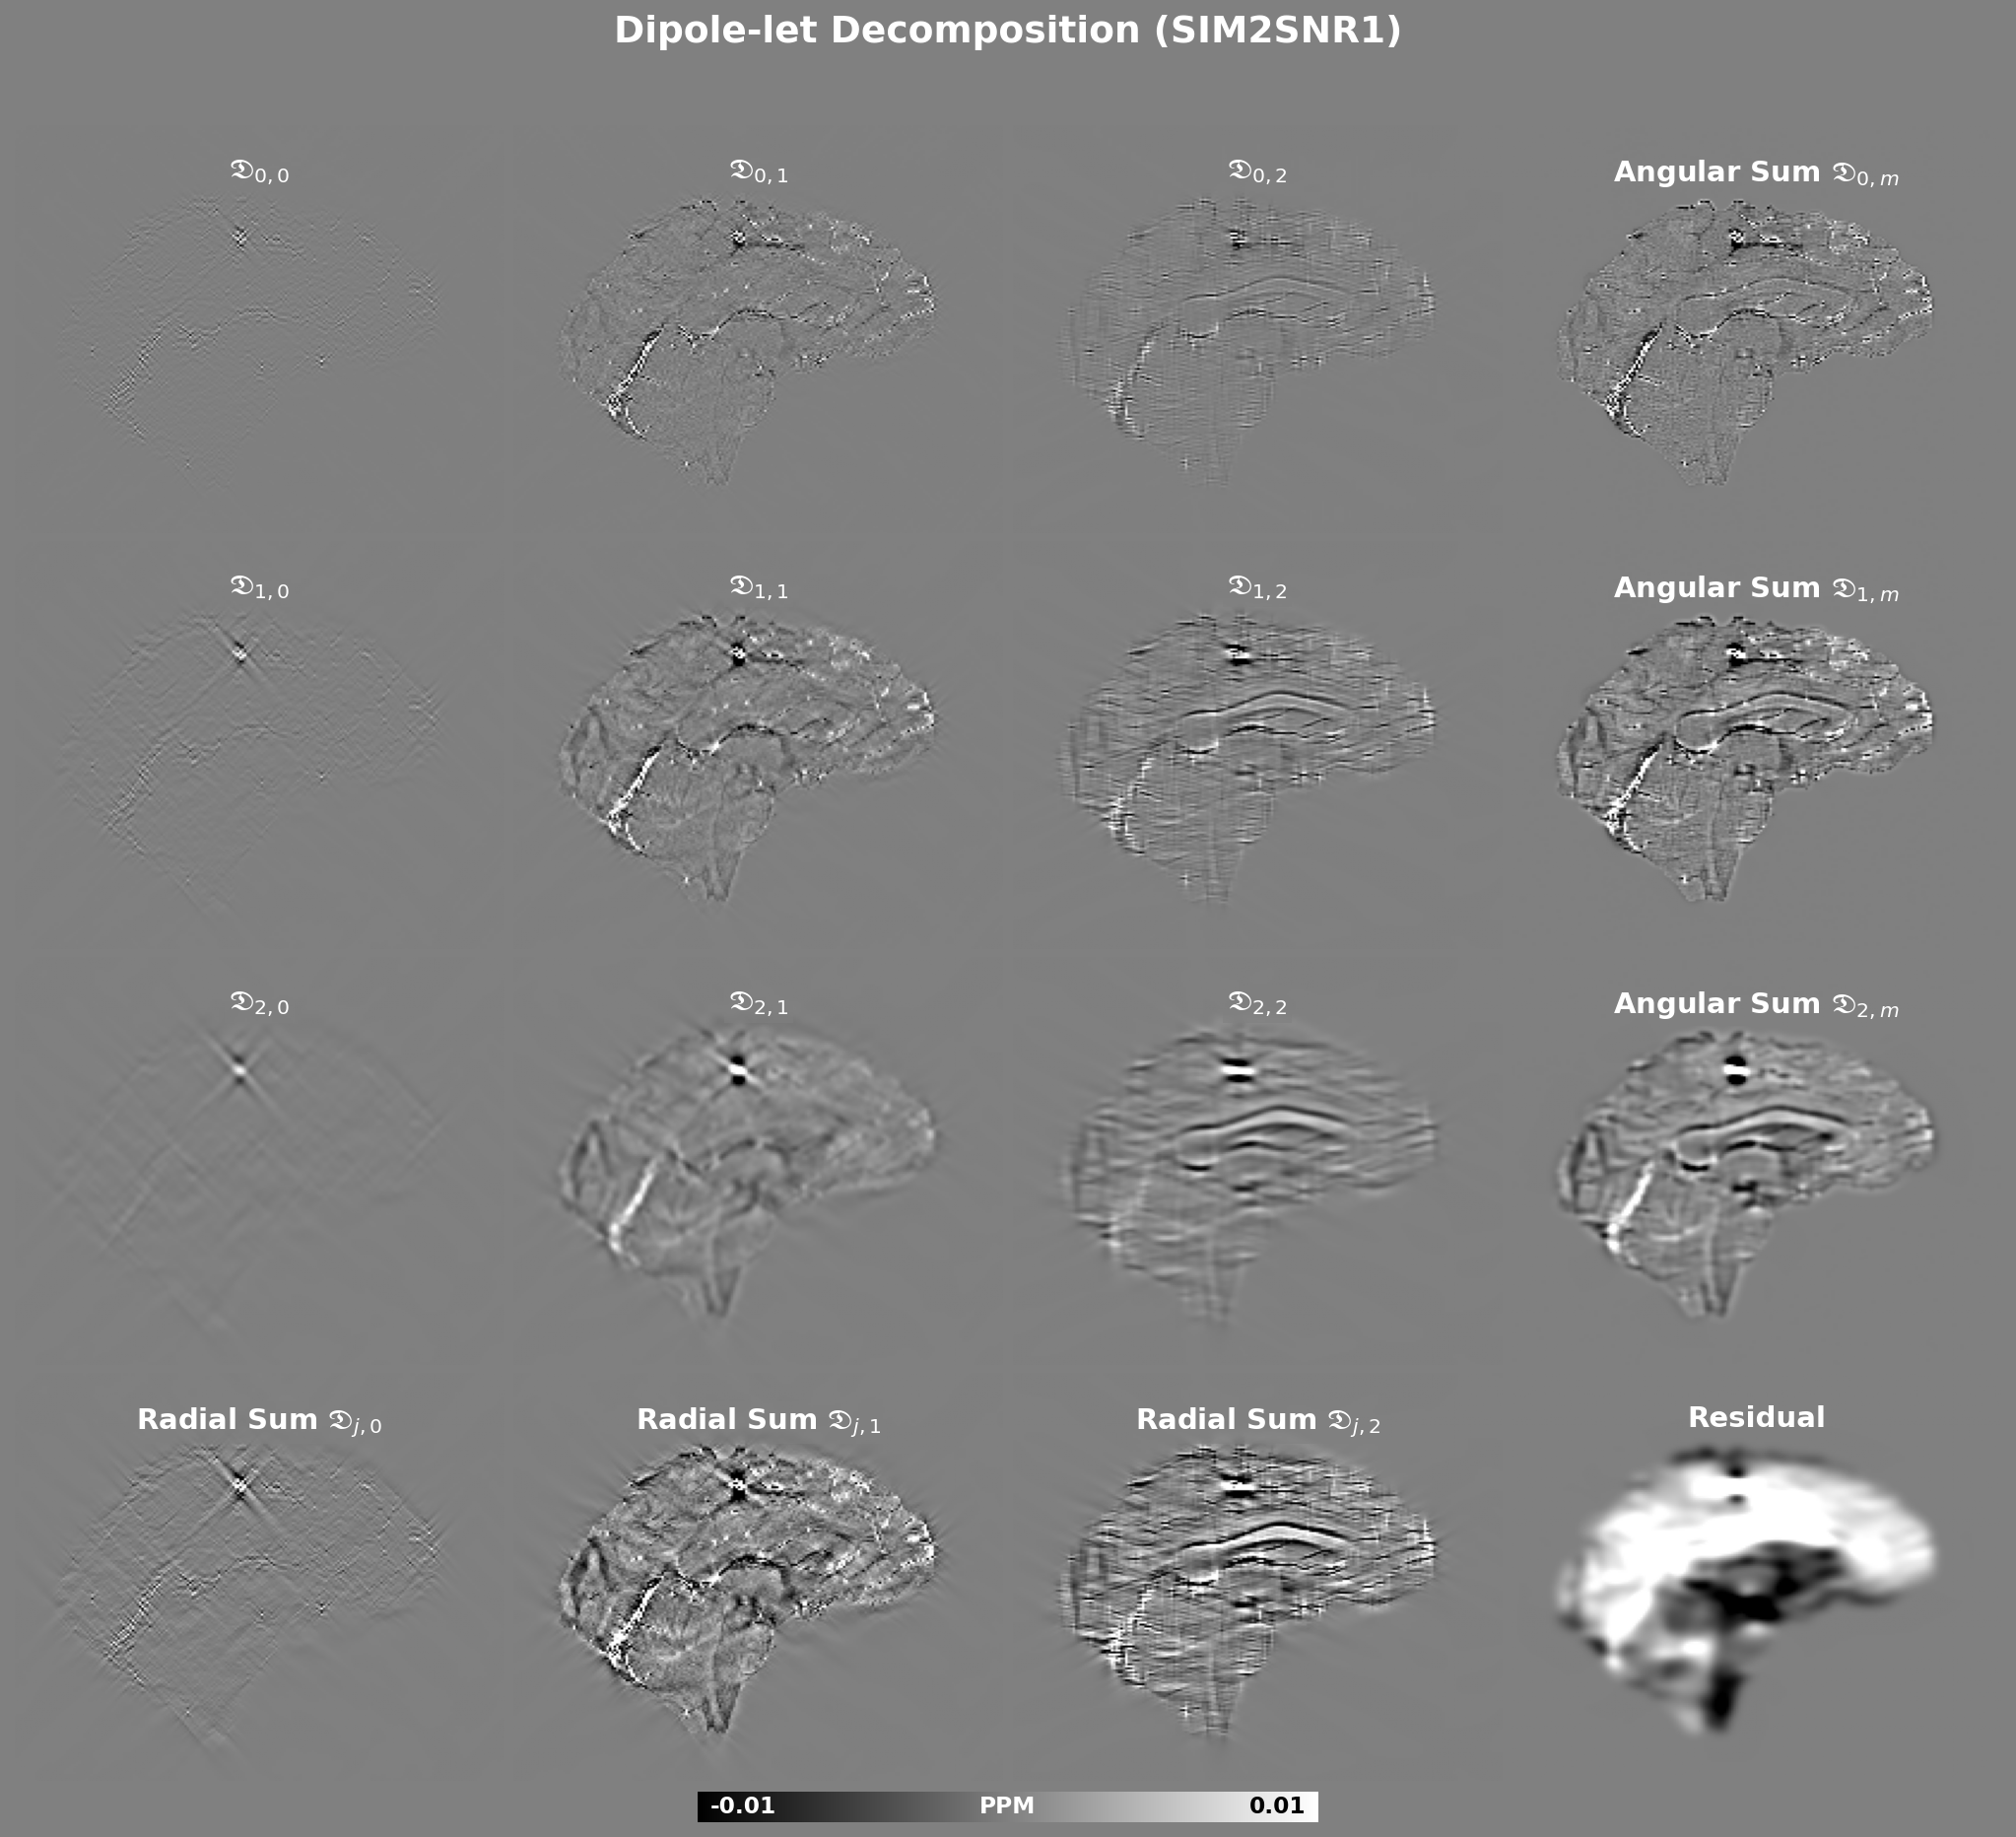

In [67]:

visualize_decomposition_with_sums(
    segmented_coeffs_sim2,
    segmented_coarse_sim2,
    slice_dim = 0,
    slice_idx = 82,
    data_name="Dipole-let Decomposition (SIM2SNR1)",
    contrast=[-0.01, 0.01],
    text_color='white',
    cmap='gray',
    cmap_bkg='grey',
    aspect='auto',
    units = 'PPM',
    fontsize=14,
    rot = (90),
    save_path=None)
#'DipoletDecom_BFRnet-FreqMap.png'